# Part D · The clinical review figure (25 marks)

One 2×2 figure from `data/vitals_10k.csv`, built from a script that runs the same way every time.
**Run order:** *Run All*. Writes `outputs/partD_figure.png` (300 dpi) and the appendix figure `outputs/partD_figure_appendix_no_hr_exclusion.png`.

Rules in force: every figure starts with `fig, ax = plt.subplots()` · no `plt.plot()` · title the finding · declare every parameter · state every exclusion with rule and count · `fig.savefig()` **before** `plt.show()`.

In [1]:
# --- Setup: finds vizlib.py and data/ wherever this notebook is saved ---------------
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_assignments_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p, p / "assignments", p / "week3" / "assignments"):
            if (cand / "vizlib.py").exists() and (cand / "data").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not find vizlib.py + data/. Save this notebook inside "
        "week3/assignments/ (next to vizlib.py) - see README.md.")

ROOT = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUT = ROOT / "outputs"            # every PNG this notebook writes lands here
OUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from vizlib import (PALETTE, MARKERS, style_defaults, save_fig, lie_factor,
                    lie_verdict, simulate_cvd, worst_pair, verdict, delta_e)

style_defaults()                  # house look, set once (slide 26)
BLUE, ORANGE, GREEN = PALETTE["series"]
print("ROOT:", ROOT)
import textwrap
from scipy import stats
LOG = {}          # the audit trail; printed at the end and used in Part E

ROOT: C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3


## Step 0 · Look before you plot

In [2]:
raw = pd.read_csv(DATA / "vitals_10k.csv")
raw.info()
display(raw.describe().T)
print("\nward values:"); print(raw.ward.value_counts())
print("\nadmit_date, first 20:"); print(raw.admit_date.head(20).tolist())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.5 MB


,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65



ward values:
ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

admit_date, first 20:
['2026-01-19', '08-Mar-2026', '2026-02-26', '27/02/2026', '09/01/2026', '01-Apr-2026', '17-Apr-2026', '24-Mar-2026', '14-Apr-2026', '02-Jan-2026', '10/03/2026', '10/02/2026', '12-Apr-2026', '29/03/2026', '17-Apr-2026', '12/02/2026', '2026-03-28', '2026-02-03', '11-Apr-2026', '08/01/2026']


### What is wrong with this file (and how each is handled)

| # | Problem (how it shows) | Handling |
|---|---|---|
| 1 | `ward`: 12 spellings for 4 wards (`Gen Medicine`, `cardio`, ` I.C.U` …) | strip + lower-case + dictionary → `ward_clean` (4 values, 0 NaN) |
| 2 | `admit_date`: three text formats from three systems | parse each with an explicit `format=`; `dd/mm/yyyy` is **day-first** (proven below) |
| 3 | `bmi` max = 999: a sentinel for "missing" | 999 → NaN |
| 4 | `bmi` min = 0: a second sentinel | 0 → NaN |
| 5 | `heart_rate` max 415 bpm: device faults | readings > 250 bpm → NaN (the rule is physiological, set before looking at any result) |
| 6 | `heart_rate` min 0: a monitor that read nothing | readings < 30 bpm → NaN |
| 7 | `map_mmhg` is **computed** `(sys + 2·dia)/3`, so its correlation with BP is arithmetic | excluded from the heatmap |
| 8 | `los_days` is extremely right-skewed (median 1.4, max 273.7) | log scale in panel 2; no rows dropped |
| 9 | `risk_score` is a **ratio** (events/day); its mean is not a rate | never averaged; see the pooled-rate check below |

Also: `systolic` is **bimodal** (panel 1), and `spo2` has a hard ceiling at 100.

In [3]:
# --- the proof that dd/mm/yyyy is day-first, not month-first -------------------------
slash = raw.admit_date[raw.admit_date.str.contains("/")].str.split("/", expand=True).astype(int)
print(f"slash-format rows: {len(slash):,}")
print(f"  first field  > 12 in {(slash[0] > 12).sum():,} rows  (max {slash[0].max()})  -> must be the DAY")
print(f"  second field > 12 in {(slash[1] > 12).sum():,} rows  (max {slash[1].max()})  -> must be the MONTH")

slash-format rows: 3,253
  first field  > 12 in 1,933 rows  (max 31)  -> must be the DAY
  second field > 12 in 0 rows  (max 4)  -> must be the MONTH


## Step 1 · Clean it, and write down every rule

In [4]:
WARD_MAP = {"general medicine": "General Medicine", "gen medicine": "General Medicine",
            "cardiology": "Cardiology", "cardio": "Cardiology",
            "day surgery": "Day Surgery", "day-surgery": "Day Surgery",
            "intensive care": "ICU", "icu": "ICU", "i.c.u": "ICU"}
HR_LO, HR_HI = 30, 250       # physiologically defensible resting heart-rate range (bpm)

def clean(raw):
    df = raw.copy()
    LOG.clear()
    LOG["rows loaded"] = f"{len(df):,}"

    # 1. ward spellings ---------------------------------------------------------------
    n_raw = df.ward.nunique()
    df["ward_clean"] = df.ward.str.strip().str.lower().map(WARD_MAP)
    assert df.ward_clean.nunique() == 4 and df.ward_clean.isna().sum() == 0
    LOG["ward spellings conformed"] = f"{n_raw} spellings -> 4 wards (0 unmapped)"

    # 2. dates: three explicit formats, then combine ---------------------------------
    s = df.admit_date.str.strip()
    dt = (pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
            .combine_first(pd.to_datetime(s, format="%d-%b-%Y", errors="coerce"))
            .combine_first(pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")))
    assert dt.isna().sum() == 0
    df["admit_dt"] = dt
    LOG["dates parsed"] = (f"3 formats, 0 unparsed; range {dt.min():%d %b %Y} to {dt.max():%d %b %Y}; "
                           f"dd/mm/yyyy read day-first")

    # 3/4. bmi sentinels -----------------------------------------------------------------
    bmi_before = df.bmi.mean()
    n999, n0 = int((df.bmi == 999).sum()), int((df.bmi == 0).sum())
    df["bmi"] = df.bmi.replace({999: np.nan, 0: np.nan})
    LOG["bmi sentinels removed"] = (f"{n999 + n0} values voided (999 -> {n999}, 0 -> {n0}); "
                                    f"mean {bmi_before:.2f} -> {df.bmi.mean():.2f} kg/m2")

    # 5/6. heart-rate device faults -----------------------------------------------------
    df["heart_rate_raw"] = df.heart_rate
    hr_before = df.heart_rate.mean()
    hi, lo = int((df.heart_rate > HR_HI).sum()), int((df.heart_rate < HR_LO).sum())
    df["heart_rate"] = df.heart_rate.where(df.heart_rate.between(HR_LO, HR_HI))
    LOG["heart-rate device faults removed"] = (
        f"{hi + lo} readings voided (> {HR_HI} bpm: {hi}; < {HR_LO} bpm: {lo}); "
        f"mean {hr_before:.2f} -> {df.heart_rate.mean():.2f} bpm; rows kept for all other variables")

    # 7. derived column ------------------------------------------------------------------
    resid = (df.map_mmhg - (df.systolic + 2 * df.diastolic) / 3).abs().max()
    LOG["derived column excluded"] = (f"map_mmhg = (systolic + 2*diastolic)/3 (max abs diff {resid:.2f}); "
                                      f"kept out of the heatmap")
    LOG["rows dropped"] = "0 (bad values are voided to NaN, never rows deleted)"
    return df

df = clean(raw)
for k, v in LOG.items():
    print(f"{k:<36} {v}")

rows loaded                          10,000
ward spellings conformed             12 spellings -> 4 wards (0 unmapped)
dates parsed                         3 formats, 0 unparsed; range 01 Jan 2026 to 30 Apr 2026; dd/mm/yyyy read day-first
bmi sentinels removed                486 values voided (999 -> 402, 0 -> 84); mean 66.18 -> 27.35 kg/m2
heart-rate device faults removed     37 readings voided (> 250 bpm: 29; < 30 bpm: 8); mean 78.83 -> 78.05 bpm; rows kept for all other variables
derived column excluded              map_mmhg = (systolic + 2*diastolic)/3 (max abs diff 0.03); kept out of the heatmap
rows dropped                         0 (bad values are voided to NaN, never rows deleted)


In [5]:
# --- 8/9. two things we do NOT "fix", but must handle correctly ---------------------
# los_days: skew
print(f"los_days: median {df.los_days.median():.2f}, mean {df.los_days.mean():.2f}, max {df.los_days.max():.2f}, "
      f"skew {stats.skew(df.los_days):.1f}; zero-day stays: {(df.los_days == 0).sum()}")

# risk_score is a RATIO: events per inpatient day. events = risk_score * los_days.
df["events"] = df.risk_score * df.los_days
by_ward = df.groupby("ward_clean").apply(lambda g: pd.Series({
    "mean of ratios (WRONG)": g.risk_score.mean(),
    "pooled rate = sum(events)/sum(days) (RIGHT)": g.events.sum() / g.los_days.sum()}), include_groups=False)
display(by_ward.round(3).sort_values("pooled rate = sum(events)/sum(days) (RIGHT)", ascending=False))
print("The two methods rank the wards differently, which is why a ratio can only be aggregated from its numerator and denominator.")

los_days: median 1.38, mean 2.31, max 273.65, skew 22.8; zero-day stays: 2


,mean of ratios (WRONG),pooled rate = sum(events)/sum(days) (RIGHT)
ward_clean,,
ICU,1.381,0.767
General Medicine,1.031,0.650
Cardiology,0.912,0.574
Day Surgery,1.423,0.398


The two methods rank the wards differently, which is why a ratio can only be aggregated from its numerator and denominator.


In [6]:
# --- which columns are NOT normally distributed? ---------------------------------------
cont = ["age", "systolic", "diastolic", "heart_rate", "spo2", "bmi", "chol_mmol_l", "glucose_mmol_l", "los_days"]
norm = pd.DataFrame({c: {"skew": stats.skew(df[c].dropna()), "excess kurtosis": stats.kurtosis(df[c].dropna())}
                     for c in cont}).T
norm["flag"] = np.where((norm["skew"].abs() > 1) | (norm["excess kurtosis"].abs() > 1), "not normal", "")
display(norm.round(2))
print("systolic has near-zero skew but kurtosis about -1.3: a flat, two-humped shape. Skew alone would miss it, so we plot it.")

,skew,excess kurtosis,flag
age,-0.01,-0.31,
systolic,0.35,-1.29,not normal
diastolic,0.24,-0.79,
heart_rate,-0.01,0.04,
spo2,-1.35,2.80,not normal
bmi,0.02,-0.11,
chol_mmol_l,0.02,-0.09,
glucose_mmol_l,1.47,2.96,not normal
los_days,22.75,556.67,not normal


systolic has near-zero skew but kurtosis about -1.3: a flat, two-humped shape. Skew alone would miss it, so we plot it.


## Step 2 · The figure

wrote C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3\outputs\partD_figure.png


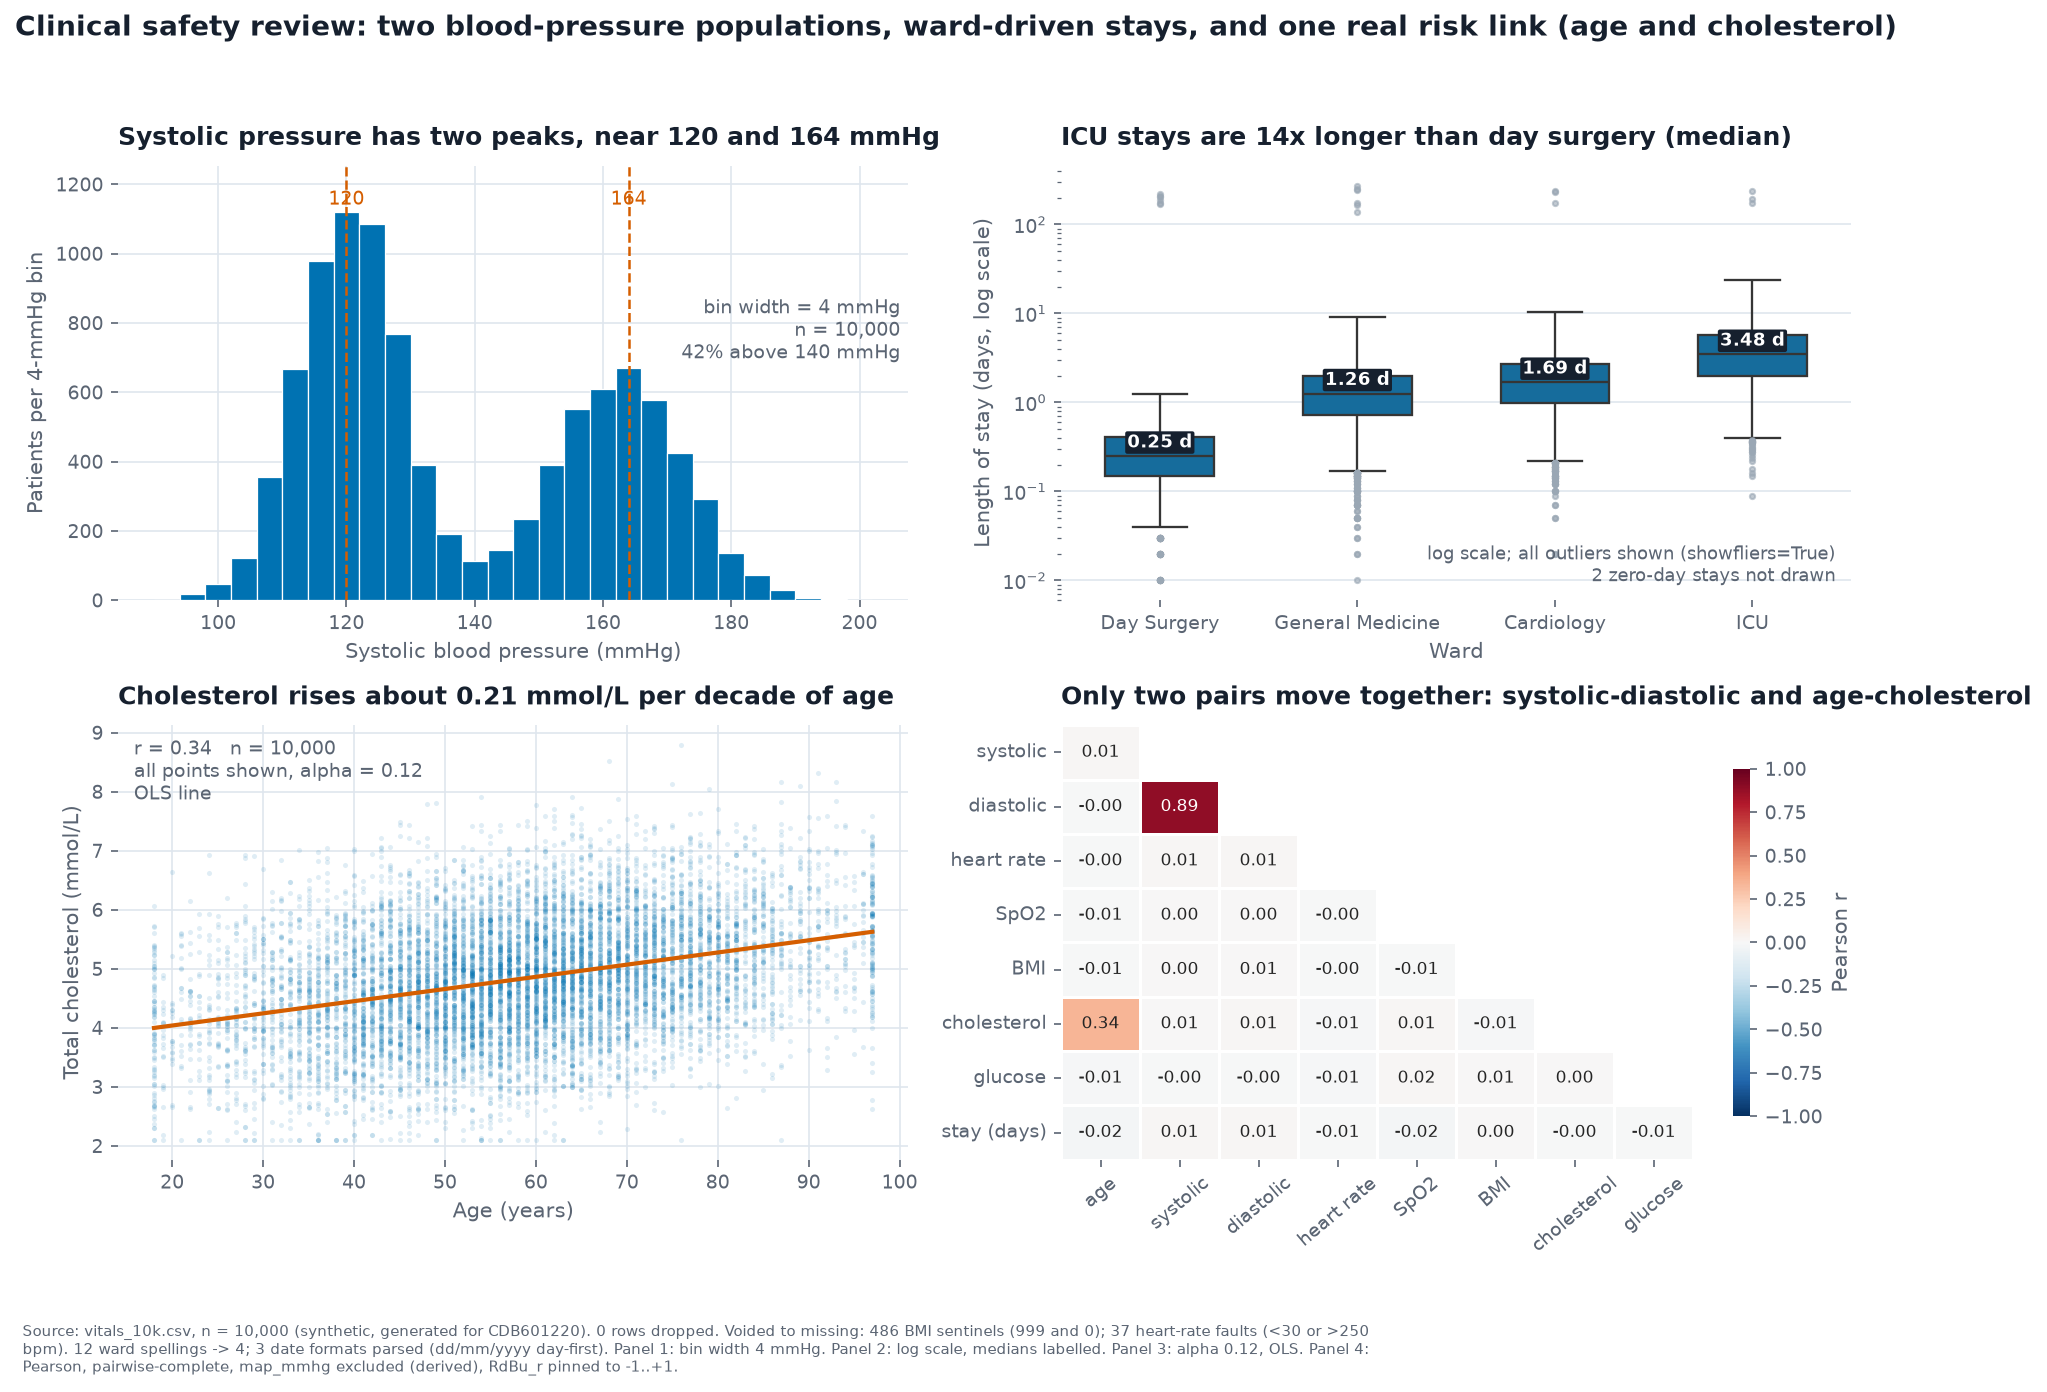

In [7]:
def build_figure(df, hr_col="heart_rate", suffix=""):
    """2x2 clinical review figure. `hr_col` lets the appendix use the un-excluded heart rate."""
    fig, ax = plt.subplots(2, 2, figsize=(12.6, 8.6))

    # ---------------- panel 1: distribution -------------------------------------------
    # Q: is systolic BP one population or several?
    BINW = 4                                           # mmHg, declared; Freedman-Diaconis gives 3.8
    edges = np.arange(90, 204, BINW)
    a = ax[0, 0]
    counts, _, _ = a.hist(df.systolic, bins=edges, color=BLUE, edgecolor="white", lw=0.6)
    centers = (edges[:-1] + edges[1:]) / 2
    lo_mode = centers[:np.searchsorted(centers, 135)][counts[:np.searchsorted(centers, 135)].argmax()]
    hi_mode = centers[np.searchsorted(centers, 135):][counts[np.searchsorted(centers, 135):].argmax()]
    share_hi = (df.systolic > 140).mean()
    for m in (lo_mode, hi_mode):
        a.axvline(m, color=PALETTE["highlight"], ls="--", lw=1.2)
        a.text(m, counts.max() * 1.02, f"{m:.0f}", color=PALETTE["highlight"], ha="center", fontsize=9)
    a.set_ylim(0, counts.max() * 1.12)
    a.set_title(f"Systolic pressure has two peaks, near {lo_mode:.0f} and {hi_mode:.0f} mmHg")
    a.set_xlabel("Systolic blood pressure (mmHg)")
    a.set_ylabel(f"Patients per {BINW}-mmHg bin")
    a.text(0.99, 0.62, f"bin width = {BINW} mmHg\nn = {len(df):,}\n{share_hi:.0%} above 140 mmHg",
           transform=a.transAxes, ha="right", va="center", fontsize=9, color=PALETTE["ink_soft"])

    # ---------------- panel 2: box plot across wards ---------------------------------
    # Q: do wards differ in length of stay?  (log scale; sorted by median)
    b = ax[0, 1]
    pos = df[df.los_days > 0]                         # 2 zero-day stays cannot sit on a log axis
    order = pos.groupby("ward_clean").los_days.median().sort_values().index.tolist()
    sns.boxplot(data=pos, x="ward_clean", y="los_days", order=order, ax=b,
                color=BLUE, log_scale=True, width=0.55, fliersize=2.5, linewidth=1.1,
                flierprops={"markerfacecolor": PALETTE["muted"], "markeredgecolor": PALETTE["muted"], "alpha": 0.6})
    meds = pos.groupby("ward_clean").los_days.median()
    for i, w in enumerate(order):
        b.text(i, meds[w] * 1.12, f"{meds[w]:.2f} d", ha="center", va="bottom", fontsize=8.5,
               color="white", fontweight="bold", bbox=dict(boxstyle="round,pad=0.12", fc=PALETTE["ink"], ec="none"))
    b.set_title(f"ICU stays are {meds['ICU'] / meds['Day Surgery']:.0f}x longer than day surgery (median)")
    b.set_xlabel("Ward"); b.set_ylabel("Length of stay (days, log scale)")
    b.text(0.98, 0.03, f"log scale; all outliers shown (showfliers=True)\n{(df.los_days == 0).sum()} zero-day stays not drawn",
           transform=b.transAxes, ha="right", va="bottom", fontsize=8.5, color=PALETTE["ink_soft"])

    # ---------------- panel 4 first (it chooses panel 3's pair) ----------------------
    heat_cols = ["age", "systolic", "diastolic", hr_col, "spo2", "bmi", "chol_mmol_l", "glucose_mmol_l", "los_days"]
    labels = ["age", "systolic", "diastolic", "heart rate", "SpO2", "BMI", "cholesterol", "glucose", "stay (days)"]
    corr = df[heat_cols].corr()                       # Pearson, pairwise-complete
    corr.index = corr.columns = labels
    corr_plot = corr.iloc[1:, :-1]                    # drop the all-empty first row / last column
    mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)   # upper triangle hidden (it says everything twice)
    d = ax[1, 1]
    sns.heatmap(corr_plot, mask=mask, cmap=PALETTE["diverging"], vmin=-1, vmax=1, center=0,
                annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.6, linecolor="white",
                cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=d)
    d.grid(False)
    d.set_title("Only two pairs move together: systolic-diastolic and age-cholesterol")
    d.tick_params(axis="x", rotation=40)
    d.tick_params(axis="y", rotation=0)

    # ---------------- panel 3: the one pair worth plotting ---------------------------
    # Q: does cholesterol rise with age?   (the heatmap says age-chol, r ~ 0.34)
    c = ax[1, 0]
    r = df.age.corr(df.chol_mmol_l)
    slope, icpt = np.polyfit(df.age, df.chol_mmol_l, 1)
    c.scatter(df.age, df.chol_mmol_l, s=6, alpha=0.12, color=BLUE, linewidths=0)   # all 10,000 points, alpha 0.12
    xs = np.array([df.age.min(), df.age.max()])
    c.plot(xs, icpt + slope * xs, color=PALETTE["highlight"], lw=2)
    c.set_title(f"Cholesterol rises about {slope * 10:.2f} mmol/L per decade of age")
    c.set_xlabel("Age (years)"); c.set_ylabel("Total cholesterol (mmol/L)")
    c.text(0.02, 0.97, f"r = {r:.2f}   n = {len(df):,}\nall points shown, alpha = 0.12\nOLS line",
           transform=c.transAxes, ha="left", va="top", fontsize=9, color=PALETTE["ink_soft"])

    # ---------------- finish ---------------------------------------------------------
    fig.suptitle("Clinical safety review: two blood-pressure populations, ward-driven stays, and one real risk link (age and cholesterol)",
                 x=0.006, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
    for p in ax.flat:                                  # spines off, every panel
        for s in ("top", "right", "left", "bottom"):
            p.spines[s].set_visible(False)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    return fig, corr

def source_note(extra=""):
    n_bmi = LOG["bmi sentinels removed"].split(" values")[0]
    n_hr = LOG["heart-rate device faults removed"].split(" readings")[0]
    txt = (f"Source: vitals_10k.csv, n = 10,000 (synthetic, generated for CDB601220). 0 rows dropped. "
           f"Voided to missing: {n_bmi} BMI sentinels (999 and 0); {n_hr} heart-rate faults (<30 or >250 bpm). "
           f"12 ward spellings -> 4; 3 date formats parsed (dd/mm/yyyy day-first). "
           f"Panel 1: bin width 4 mmHg. Panel 2: log scale, medians labelled. Panel 3: alpha 0.12, OLS. "
           f"Panel 4: Pearson, pairwise-complete, map_mmhg excluded (derived), RdBu_r pinned to -1..+1. {extra}")
    return "\n".join(textwrap.wrap(txt, 175))

fig, corr = build_figure(df)
print("wrote", save_fig(fig, OUT / "partD_figure.png", source_note()))   # SAVE first ...
plt.show()                                                              # ... then show

### What each panel answers (one sentence each)

1. **Distribution:** is systolic pressure one population? *No: two humps, centred near 120 and 164 mmHg, with 42% of patients above 140.*
2. **Box plot:** do wards differ in length of stay? *Yes: ICU stays are about 14× longer than day surgery at the median.* Stays are so right-skewed (max 273 days) that a linear axis collapses every box to a line, so the axis is log.
3. **Scatter:** which risk indicator is worth a closer look? *Cholesterol rises with age (r = 0.34).* Systolic–diastolic is also high (0.89), but those are two readings of the same blood pressure, so it is not a finding. `map_mmhg` was excluded because it is computed from them.
4. **Heatmap:** which indicators move together? It is the screening tool that picked panel 3's pair. Every other cell is ≈ 0.

## Appendix figure · the same figure **without** the heart-rate exclusion
The ethics clause: the exclusion is correct, but the reader must be able to see what it changed.

wrote C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3\outputs\partD_figure_appendix_no_hr_exclusion.png


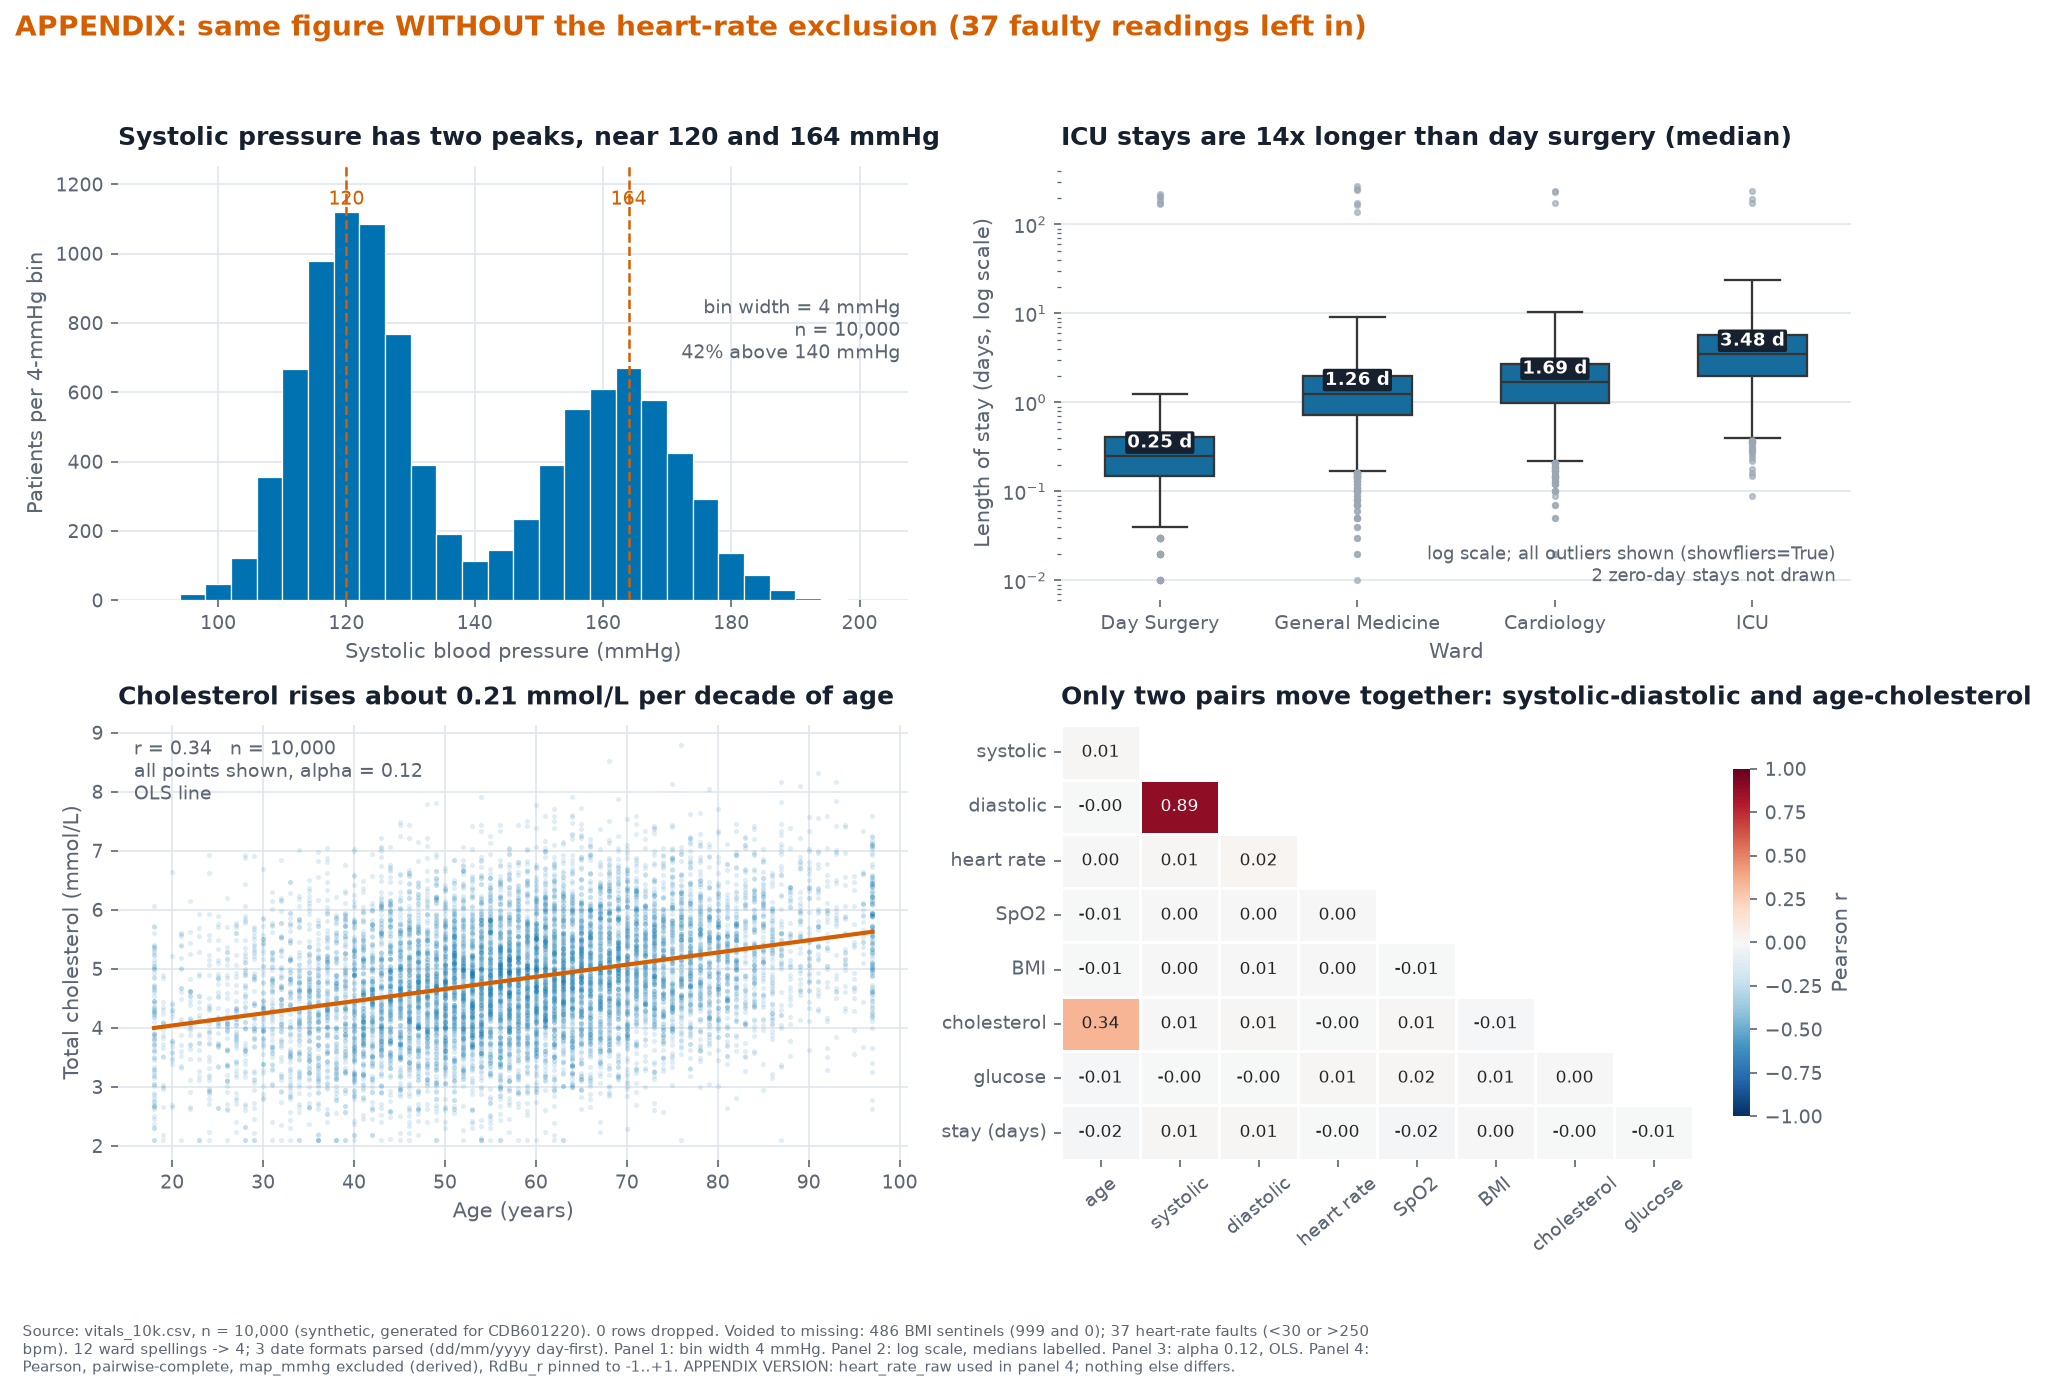


Largest change to any heart-rate correlation from the exclusion: 0.021


In [8]:
fig_app, corr_app = build_figure(df, hr_col="heart_rate_raw", suffix=" (appendix)")
fig_app.suptitle("APPENDIX: same figure WITHOUT the heart-rate exclusion (37 faulty readings left in)",
                 x=0.006, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["highlight"])
note_app = source_note("APPENDIX VERSION: heart_rate_raw used in panel 4; nothing else differs.")
print("wrote", save_fig(fig_app, OUT / "partD_figure_appendix_no_hr_exclusion.png", note_app))
plt.show()

hr_rows = [c for c in corr.index if c == "heart rate"]
chg = (corr_app.loc["heart rate"] - corr.loc["heart rate"]).drop("heart rate").abs()
print(f"\nLargest change to any heart-rate correlation from the exclusion: {chg.max():.3f}")

## `.melt()` demo · why `ward_los_wide.csv` is in the folder
Seaborn wants **long** data (one row per observation). The wide file has one column per ward and ragged blanks. Passing it straight to `sns.boxplot` gives a chart of column indices, not wards.

(4018, 4) -> (10000, 2) (one row per stay)


,wide (melted) median,vitals_10k median
Cardiology,1.69,1.69
Day Surgery,0.25,0.25
General Medicine,1.26,1.26
ICU,3.48,3.48


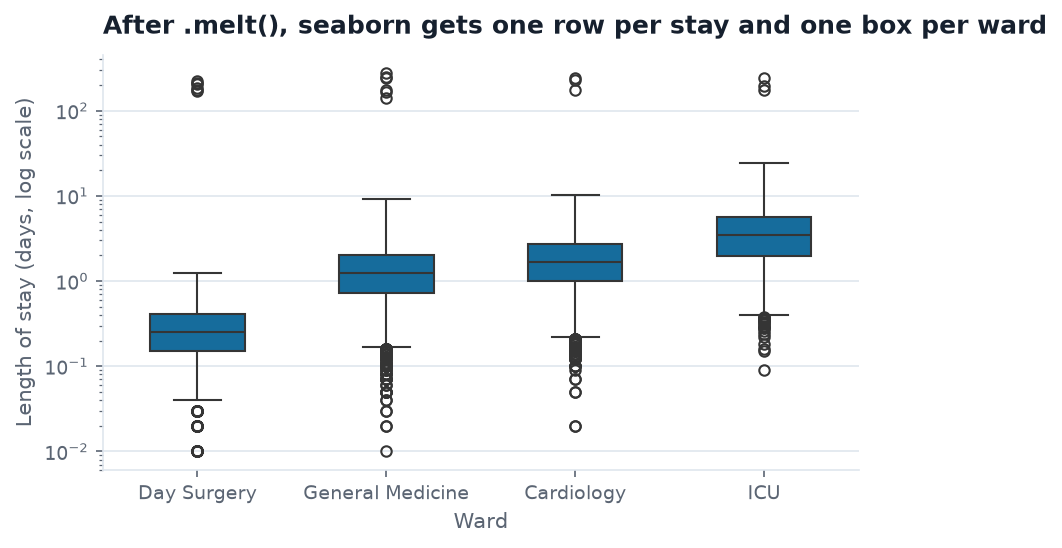

In [9]:
wide = pd.read_csv(DATA / "ward_los_wide.csv")
long = wide.melt(var_name="ward", value_name="los_days").dropna()          # wide -> long, ragged blanks dropped
long["ward"] = long.ward.str.strip().str.lower().map(WARD_MAP)
print(wide.shape, "->", long.shape, "(one row per stay)")

# does the melted wide file agree with the vitals file?
cmp = pd.DataFrame({"wide (melted) median": long.groupby("ward").los_days.median(),
                    "vitals_10k median": df.groupby("ward_clean").los_days.median()})
display(cmp.round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
order = long.groupby("ward").los_days.median().sort_values().index
sns.boxplot(data=long[long.los_days > 0], x="ward", y="los_days", order=order, color=BLUE, log_scale=True, ax=ax, width=0.5)
ax.set_title("After .melt(), seaborn gets one row per stay and one box per ward")
ax.set_xlabel("Ward"); ax.set_ylabel("Length of stay (days, log scale)")
plt.show()

## Your cleaning log (this is Part E item 3)

In [10]:
for k, v in LOG.items():
    print(f"  {k:<36} {v}")

  rows loaded                          10,000
  ward spellings conformed             12 spellings -> 4 wards (0 unmapped)
  dates parsed                         3 formats, 0 unparsed; range 01 Jan 2026 to 30 Apr 2026; dd/mm/yyyy read day-first
  bmi sentinels removed                486 values voided (999 -> 402, 0 -> 84); mean 66.18 -> 27.35 kg/m2
  heart-rate device faults removed     37 readings voided (> 250 bpm: 29; < 30 bpm: 8); mean 78.83 -> 78.05 bpm; rows kept for all other variables
  derived column excluded              map_mmhg = (systolic + 2*diastolic)/3 (max abs diff 0.03); kept out of the heatmap
  rows dropped                         0 (bad values are voided to NaN, never rows deleted)
